# Логистичка регресија
## Предвидување на преживеани во Titanic податочното множество

Податоците за преживеаните патници од бродот Titanic ќе ги искористиме за да изградиме модел кој ќе предвидува кој има поголема веројатност да преживее.

Податочното множество ги содржи следните колони:

* **PassengerId:** Идентификациски број на патникот
* **Pclass:** Патничка класа
* **Name:** Име на патникот
* **Sex:** Пол на патникот
* **Age:** Возраст на патникот
* **SibSp:** Број на браќа-сестри/брачен другар кои што се со патникот на бродот
* **Parch:** Број на родители/деца кои што се со патникот на бродот
* **Ticket:** Број на билетот
* **fare:** Цена на билетот
* **Cabin:** Број на кабина во која бил сместен патникот
* **Embarked:** Пристаниште каде се качил патникот
* **Survival:** Дали преживеал патникот

Дополнителни информации за некои од колоните кои вие треба да ги увидите преку истражување на податоците:

    Pclass:
        1st = Прва класа
        2nd = Средна класа
        3rd = Ниска класа
        
    sibsp: Роднинските врска можат да бидат претставени на следниот начин...
        Sibling = брат, сестра, полубрат, полусестра
        Spouse = Сопруг, сопруга (верениците се игнорирани)

    parch: Роднинските врска можат да бидат претставени на следниот начин
        Parent = мајка, татко
        Child = ќерка, син, полусин, полуќерка
        Некои деца патувале само со дадилка, последователно parch=0 за нив.

## Користени библиотеки

In [328]:
import pandas as pd
import numpy as np
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, balanced_accuracy_score

## Вчитување на податоците

1. Со помош на библиотеката pandas, сместете ги податоците во променлива по име titanic_train
2. Прикажете ги првите 5 редици од прочитаната табела
3. Прикажете општи информации за прочитаните податоци како: податочен тип на секоја колона (feature), број на non-null редици за секоја колона, име на колона, итн.
4. Прикажете општи статистички метрики за секоја од колоните. Зошто колоната за име е изоставена?

**помош: read_csv(), head(), info(), describe(), .columns**

In [329]:
titanic_train = pd.read_csv("titanic_train.csv")
titanic_train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [330]:
titanic_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [331]:
titanic_train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Колоната за име е изоставена бидејќи е објект

#### Забележете го количеството на RAM меморија кое е потребно за прочитаните податоци при употреба на .info() функцијата.

Забележете ја минималната и максималната вредност за секоја од колоните и проичитајте ги податоците одново така што ќе примените соодветни податочни типови кои зафаќаат помалку меморија како: uint8, float16, bool, итн. 

**помош: pandas.read_csv(dtype=...)**

In [332]:
titanic_train = pd.read_csv("titanic_train.csv", dtype={'PassengerId': np.uint8, 'Survived': bool, 'Pclass': np.uint8, 'SibSp': np.uint8, 'Parch': np.uint8, 'Fare': np.float16})

In [333]:
titanic_train['Age'] = titanic_train['Age'].astype(np.float32)

#### Приметете колку сте заштедиле меморија при користење на соодветните податочни типови

**помош: info()**

In [334]:
titanic_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    uint8  
 1   Survived     891 non-null    bool   
 2   Pclass       891 non-null    uint8  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float32
 6   SibSp        891 non-null    uint8  
 7   Parch        891 non-null    uint8  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float16
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: bool(1), float16(1), float32(1), object(5), uint8(4)
memory usage: 44.5+ KB


## Истражување и визуелизација на податоците

#### Застапеност на NaN вредности
Отворете ја titanic_train.csv табелата и забележете дали постојат NaN вредности за некој од податоците.

Олеснете си ја работата така што ќе креирате визуелна мапа на сите NaN вредности во податочното множество.

**помош: seabron.heatmap(), pandas.*.isna()**



In [335]:
titanic_train.isna()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,False,False,False,False,False,False,False,False,False,False,True,False
1,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,True,False
3,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
886,False,False,False,False,False,False,False,False,False,False,True,False
887,False,False,False,False,False,False,False,False,False,False,False,False
888,False,False,False,False,False,True,False,False,False,False,True,False
889,False,False,False,False,False,False,False,False,False,False,False,False


<Axes: >

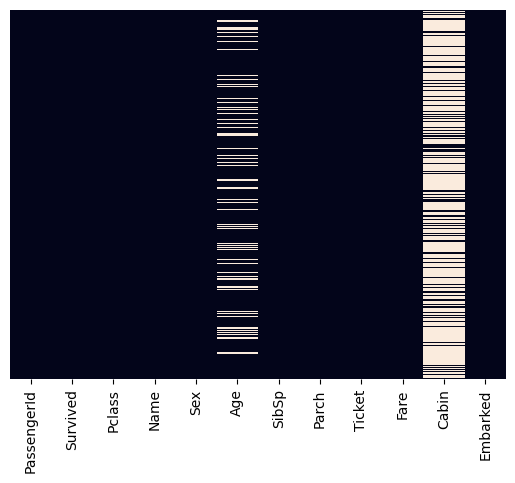

In [336]:
sns.heatmap(titanic_train.isna(),  cbar=False, yticklabels=False)

Множеството содржи многу редици кај кои недостасува вредност во колоната за Кабина и Возраст. Понатамошно ќе треба да се искористи оваа информација за да се одлучи што ќе се прави со овие вредности кои недостасуваат. Во подолните ќелие ќе покажеме повеќе пристапи.

#### Со помош на график проверете дали податочното множество е балансирано или не?
Балансирано множество подразбира дека бројот на преживеани и загинати е еднаков (50%/50%). Небалансирани множества се оние каде што едната класа е драстично поголема на број во однос на другата.

**помош: seaborn.countplot(x=..., data=...)**

<Axes: xlabel='Survived', ylabel='count'>

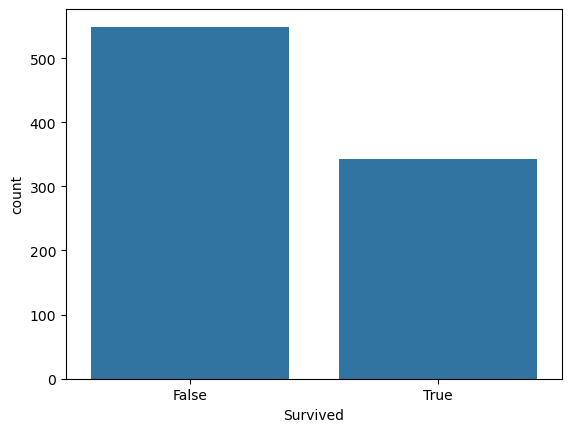

In [337]:
sns.countplot(titanic_train, x='Survived')

Од множеството може да се види дека излезната величина е нерамномерно распределена по однос на преживеани и ова мора да се земе предвид при начинот на евалуација на моделот.

#### Со помош на график проверете дали има драстична разлика во бројот на преживеани кај машкиот и женскиот пол.
Оваа информација ќе ни каже дали колоната за пол ќе ни биде корисна при тренирање на моделот.

**помош: seabron.countplot(x=..., data=..., hue=...)**

<Axes: xlabel='Survived', ylabel='count'>

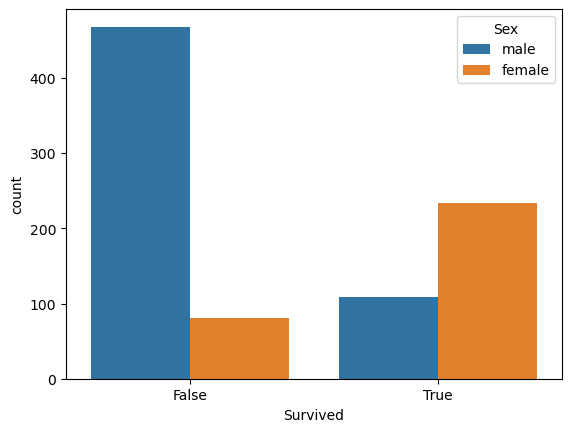

In [338]:
sns.countplot(titanic_train, x="Survived", hue='Sex')

Од дијаграмот може да се заклучи дека значително повеќе жени преживеале од мажи. Па најверојатно карактеристиката за полот ќе биде добра за да се искористи при предвидување. Овој заклучок е валиден само под услов доколку на бродот немало севкупно повеќе жени од мажи. Во спротивно логичен би бил одговорот дека преживеале повеќе жени бидејќи меѓу патниците би имало повеќе жени севкпуно.

#### Со помош на график проверете го бројот на жени наспрема мажи присутни на бродот

**помош: seaborn.countplot(x=..., data=...)**

<Axes: xlabel='Sex', ylabel='count'>

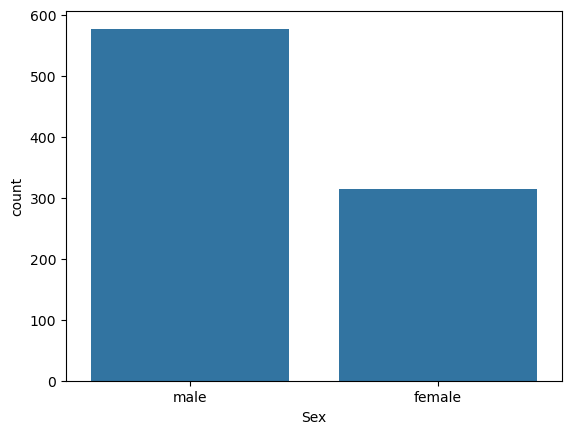

In [339]:
sns.countplot(titanic_train, x='Sex')

Од тука дефинитивно можеме да заклучиме дека полот ќе ни донесе значителна информација при предвидувањето.
Дали можеби и патничката класа би можела да биде добра карактеристика за предвидување на преживеаните?

#### Со помош на график проверете го бројот на преживеани и загинати во зависност од патничката класа.

**помош: seaborn.countplot(x=..., data=..., hue=...)**

<Axes: xlabel='Survived', ylabel='count'>

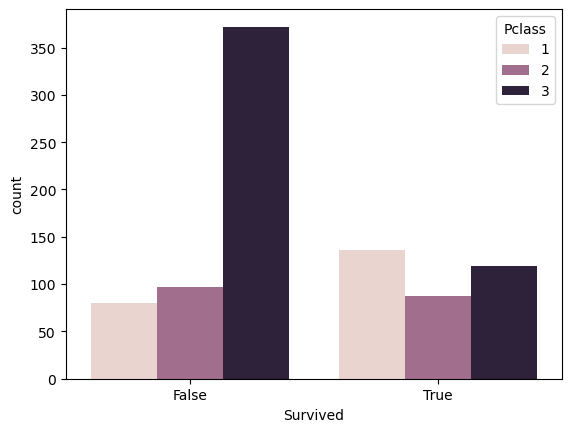

In [340]:
sns.countplot(titanic_train, x='Survived', hue='Pclass')

Може да се забележи дека значителен број од патниците кои припаѓаат на патничка класа 3 не преживеале. Дали можеби ова е резултат на тоа што севкупно поголем број од патниците на бродот припаѓале на патничка класа?

#### Со помош на график проверете го вкупниот број на патници според нивната патничка класа

**помош: seaborn.countplot(x=..., data=...)**

<Axes: xlabel='Pclass', ylabel='count'>

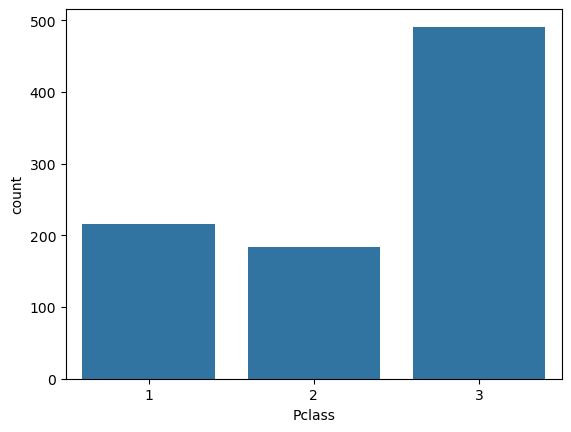

In [341]:
sns.countplot(titanic_train, x='Pclass')

Од графикот може да се забележи на бродот имало два пати повеќе патници, припадници на патничка класа 3, во однос на патници кои припаѓале на патничка класа 1. Меѓутоа од горниот график можеме да видиме дека три пати повеќе патници, припадници на патничка класа 3, загинале во споредба со патници кои припаѓале на патничка класа 1. Според ова можеме да заклучиме дека колоната за патничка класа можеме да донесе големо количество на информација при предвидување.

#### Воочете ја распределбата на возраста кај патниците со цел да забележите дали поголем дел од патници се млади или стари.

**помош: pandas.*.hist(bins=30) или seaborn.distplot()**

<Axes: >

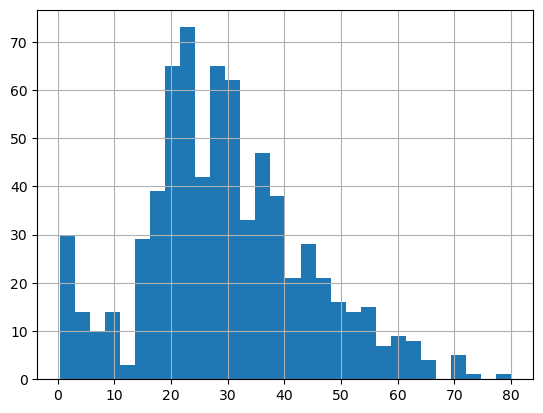

In [342]:
titanic_train['Age'].hist(bins=30)

#### Со помош на график забележете дали има драстична разлика помеѓу преживеани и загинати во однос на нивната возраст

**помош: seaborn.distplot(data.loc[data['Survived'] == ?, 'Age'].dropna(), color='b')**

/run/user/1000/app/org.jupyter.JupyterLab/ipykernel_214/1936743523.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(titanic_train.loc[titanic_train['Survived'] == 1, 'Age'].dropna(), color='g')
/run/user/1000/app/org.jupyter.JupyterLab/ipykernel_214/1936743523.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5

<Axes: xlabel='Age', ylabel='Density'>

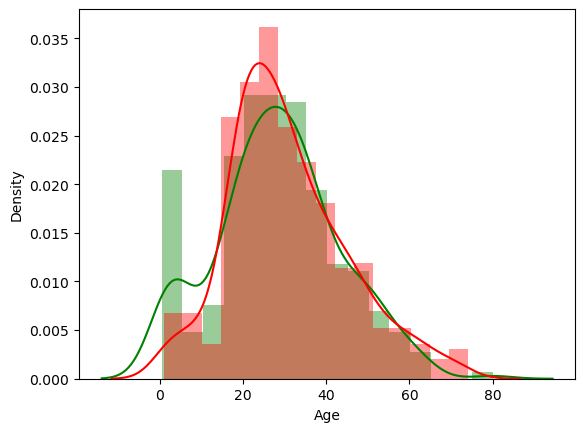

In [343]:
sns.distplot(titanic_train.loc[titanic_train['Survived'] == 1, 'Age'].dropna(), color='g')
sns.distplot(titanic_train.loc[titanic_train['Survived'] == 0, 'Age'].dropna(), color='r')

Од графикот се воочува дека значителен број на патниците кои преживеале се деца. Според тоа може да се додаде дополнителна карактеристика која ќе означува дали патникот е дете или возрасен.

#### Исцртајте го истиот график каде наместо возраста ќе ја користите цената на билетот

/run/user/1000/app/org.jupyter.JupyterLab/ipykernel_214/3087507976.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(titanic_train.loc[titanic_train['Survived'] == 1, 'Fare'].dropna(), color='g')
/run/user/1000/app/org.jupyter.JupyterLab/ipykernel_214/3087507976.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe

<Axes: xlabel='Fare', ylabel='Density'>

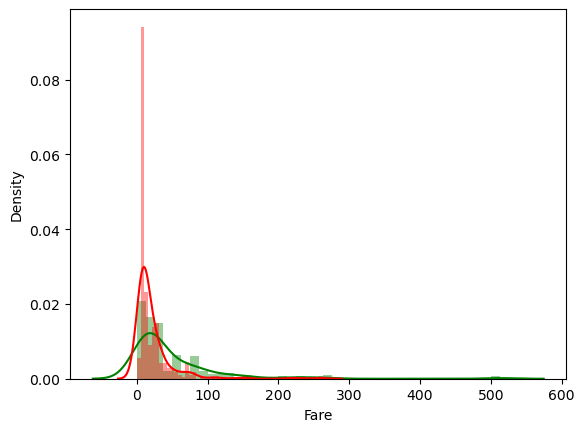

In [344]:
sns.distplot(titanic_train.loc[titanic_train['Survived'] == 1, 'Fare'].dropna(), color='g')
sns.distplot(titanic_train.loc[titanic_train['Survived'] == 0, 'Fare'].dropna(), color='r')

Забележете дека голем дел од патниците кои не преживеале имале малку поевтин билет од патниците кои преживеале. Ова може да се забележи преку растојанието по x оска помеѓу пиковите на секој од хистограмите индивидуално.

#### Исцртајте хистограм за колоните: SibSp, Parch, Fare.

1. Хистограмот за SibSp ќе ни каже дали има голем број на патници кои имаат роднини на бродот. На тој начин ќе знаеме дали оваа колона носи информација за значителен дел на патниците.
2.Хистограмот за Parch ќе ни каже дали има голем број на патници кои се со своето семејство на бордот. На тој начин ќе знаеме дали оваа колона носи информација за значителен дел на патниците.

<Axes: xlabel='SibSp', ylabel='Count'>

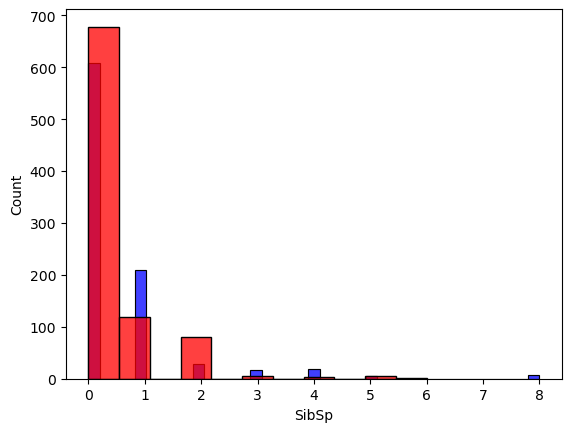

In [345]:
sns.histplot(titanic_train['SibSp'], color='b')
sns.histplot(titanic_train['Parch'], color = 'r')

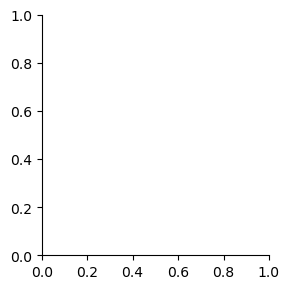

In [346]:
sns.FacetGrid(titanic_train)

**За дома:** Истражете ја функцијата **FacetGrid** од библиотеката Seaborn. Со нејзина помош би можеле да генерирате побогати графици како оние од погоре.

## Прочистување на податоците

Постојат два начина за да се справиме со податоците кои недостасуваат:
1. **Елиминација на сите редици каде недостасуваат податоци**

    Се применува само кога вредностите кои недостасуваат се многу малку на број, односно кога елиминацијата на редици нема значително до го намали податочното множество.
2. **Елиминација на цела колона**

    Се применува кога една колона од табелата има големо количество од податоците кои недостасуваат. Во овој случај поисплатливо е да се елиминира цела колона отколку сите редици каде недостасуваат податоци во таа колона.

3. **Пополнување на податоците кои недостасуваат** - (Data Imputation)

    Податоците кои недостасуваат се пополниуваат со помош на информација од постоечките податоци во табелата. Новопополнетите податоци веројатно нема да бидат исти како вистинските, но ќе претставуваат приближна вредност. На овој начин се овозможува да се искористи информацијата од редиците(колоните) кои инаку би се избришале и на тој начин се добива можност да се подобри точноста на моделот при предвидување.
    
### Справување со податоците кои недостасуваат во колоната Embarked
Проверете колкав број на редици постојат кои имаат NaN вредност во колоната Embarked.

**помош: data['Embarked'].isna() или data.info()**

In [347]:
titanic_train['Embarked'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 891 entries, 0 to 890
Series name: Embarked
Non-Null Count  Dtype 
--------------  ----- 
889 non-null    object
dtypes: object(1)
memory usage: 7.1+ KB


In [243]:
titanic_train['Embarked'].isna()

0      False
1      False
2      False
3      False
4      False
       ...  
886    False
887    False
888    False
889    False
890    False
Name: Embarked, Length: 891, dtype: bool

Со оглед на тоа што се работи за само две редици можеме да ја примениме метода 1 така што ќе ги елиминираме сите редици со NaN вредност, за оваа колона.

**помош: pandas.*.dropna(axis=..., subset=...)**

In [244]:
titanic_train.dropna(subset = ['Embarked'], inplace = True)
titanic_train['Embarked'].info()

<class 'pandas.core.series.Series'>
Index: 889 entries, 0 to 890
Series name: Embarked
Non-Null Count  Dtype 
--------------  ----- 
889 non-null    object
dtypes: object(1)
memory usage: 13.9+ KB


Користете го аргументот inplace=True ако не сакате излезот од dropna() функцијата да го сместувате во нова променлива. Односно, ако сакате функцијата да ја направи промената врз постоечката табела.

### Справување со податоците кои недостасуваат во колоната Cabin
Секое поле за кабината на патникот е од тип „X1X2“ каде X1 е секторот на бродот, а X2 е бројот на кабината. Податоците за кабината на патникот можат да содржат значајна информација од аспект на тоа дали патникот бил сместен на подолните спратови од бродот или близу палубата. Во идеален случај би можело да се извлече секторот како нова карактеристика каде што недостатокот на кабината како поле за патникот може да значи дека тој воопшто немал резервирано кабина. Ова нека остане како вежба за студентот, а во овој случај ќе ја примениме метода 3 и ќе ја елиминираме цела колона.

#### Елиминирајте ја цела колона под името Cabin
**помош: pandas.*.drop(columns=...)**

In [245]:
titanic_train.drop(columns = 'Cabin', inplace = True)

In [246]:
titanic_train.head()

/home/rademicov/.var/app/org.jupyter.JupyterLab/config/jupyterlab-desktop/jlab_server/lib/python3.12/site-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,False,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.250000,S
1,2,True,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.312500,C
2,3,True,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.925781,S
3,4,True,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.093750,S
4,5,False,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.046875,S


### Справување со податоците кои недостасуваат во колоната Age
Со оглед на тоа што за голем број на патници не е позната возраста, би било непрактично доколку се отстранат толку многу редици со вредност Nan. Од друга страна не би било практично да се отстрани колоната за возраст бидејќи таа е значајна карактеристика за предвидување на преживеаните кај патниците со помала возраст(деца). Во овој случај ќе ги пополниме вредностите кои што недостасуваат според информации добиени од постоечките податоци на табелата.

Еден пристап би било да се најде просечната возраст на патниците и таа да се пополни на местото каде што недостасува. Сепак можеме да го подобриме овој пристап така што, секаде каде што недостасува возраста ќе пополниме просечна возраст во зависност од вредноста во другите колони(патничка класа, пол, цена на билет итн.). Вообичаено патници кои купуваат поскапа карта, или се од повисока патничка класа се на постара возраст. На овој начин ќе се обидеме да инферираме поточна возраст за секој од патници кои го немаат овој податок.

Ќе ги пресметаме средните возрасти според конкретен пол и патничка класа, па ќе видиме дали истите влијаат на возраста на патникот.

#### Пронајдете ја средната возраст за секој пол и секоја патничката класа по парови
Поради комплексноста на решението на овој проблем истото е дадено во прилог. Ентузијастите можат да се обидат сами да го решат проблемот. 

**Откријте ја ќелијатa за да го видите решението.**

In [247]:
means = titanic_train.groupby(['Sex', 'Pclass'])['Age'].mean()
means

Sex     Pclass
female  1         34.240963
        2         28.722973
        3         21.750000
male    1         41.281384
        2         30.740707
        3         26.507589
Name: Age, dtype: float32

Со оглед на тоа дека има разлика во средните вредности кај секоја од паровите по пол и класа, можеме да ги искористиме овие колони за да ги пополниме вредностите кои недостасуваат. На овој начин би добиле поблиски возрасти до реалните.

#### Сместете ги средните возрасти за секој пар од (пол, патничка класа) на местата каде што постојат NaN вредности
Поради комплексноста на решението на овој проблем истото е дадено во прилог. Ентузијастите можат да се обидат сами да го решат проблемот. 

**Откријте ја ќелијата за да го видите решението.**

In [248]:
for sex, pclass in means.index:
    titanic_train.loc[titanic_train['Age'].isnull() & (titanic_train['Sex'] == sex) & (titanic_train['Pclass'] == pclass), 'Age'] = means[sex][pclass]

In [249]:
titanic_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 889 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  889 non-null    uint8  
 1   Survived     889 non-null    bool   
 2   Pclass       889 non-null    uint8  
 3   Name         889 non-null    object 
 4   Sex          889 non-null    object 
 5   Age          889 non-null    float32
 6   SibSp        889 non-null    uint8  
 7   Parch        889 non-null    uint8  
 8   Ticket       889 non-null    object 
 9   Fare         889 non-null    float16
 10  Embarked     889 non-null    object 
dtypes: bool(1), float16(1), float32(1), object(4), uint8(4)
memory usage: 44.3+ KB


## Справување со категорички карактеристики
Едно податочно множество може да има два типа на карактеристики и секој од овие типови треба да се третираат посебно при процесирање на податоците.

1. **Нумерички карактеристики:**
    
    Уште се нарекуваат квантитативни карактеристики чии податоци се опишуваат со помош на бројна вредност. Типичен пример за овие карактеристики се возраст, маса, висина, број на гласови, број на учесници, итн. Секогаш може да се извршуваат математички операции на овие карактеристики и нивните резултатите би давале логички вредности кои можат да се применат како: средна вредност, медијана, производ/разлика/количник од две или повеќе карактеристики итн.
2. **Категорички карактеристики:** 

    Овие карактеристики уште се нарекуваат квалитативни карактеристики и тие опишуваат припадност на определена категорија. Типичен пример за нив би било пол, бренд на продукт, тип на возило, град, држава, итн. Извршување на математички операции на овој тип на карактеристики би било нелогично и затоа тие не треба да се претставуваат како една карактеристика каде посебна нумеричка вредност се доделува на секоја категорија. Доколку тие се претстават како нумеричка карактеристика тогаш ризикуваме моделот да пронаоѓа математички зависности кои во реалноста тие не постојат. На пр. доколку една карактеристика за бренд на возило е претставена на следниот начин {BWM: 0, Audi: 1, Honda: 2} тогаш ризикуваме моделот да пронајде дека Honda е два пати поголема од Audi. Во такви случаи може да се наруши прецизноста на предвидување на моделот.

    Постојат посебен тип на категорички карактеристики кои уште се нарекуваат ординални карактеристики или подредени. Типичен пример за тоа е патничка класа {Прва класа: 1, Средна класа: 2, Ниска класа: 3}. Иако подреденоста на секоја од патничките класа е евидентна според комфорот и цената на билетот, сепак нивната бројна вредност не значи дека ја опишува истата разлика како реалната разлика на цената и комфорот.

Според горе наведеното увидување, потребно е да се направи трансформација на сите категорички карактеристики како: Pclass, Sex, Embarked.

### Колона: Sex
#### Променете ги текстуалните вредности во колоната Sex со помош на нумерички вредности од типот на: {'male': 0, 'female': 1}

**помош: pandas.*.map()**

In [250]:
titanic_train['Sex'] = titanic_train['Sex'].map({'male': 0, 'female': 1})

In [251]:
titanic_train['Sex'] = titanic_train['Sex'].astype(bool)
titanic_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 889 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  889 non-null    uint8  
 1   Survived     889 non-null    bool   
 2   Pclass       889 non-null    uint8  
 3   Name         889 non-null    object 
 4   Sex          889 non-null    bool   
 5   Age          889 non-null    float32
 6   SibSp        889 non-null    uint8  
 7   Parch        889 non-null    uint8  
 8   Ticket       889 non-null    object 
 9   Fare         889 non-null    float16
 10  Embarked     889 non-null    object 
dtypes: bool(2), float16(1), float32(1), object(3), uint8(4)
memory usage: 38.2+ KB


### Колона: Pclass
Оваа колона содржи три различни вредности. Според тоа нема да можеме да го користиме истиот пристап како во случајот за колоната Sex. За таа намена ќе искористиме пристап за транформација на категорички карактеристики кој што се вика one-hot encoding.
#### Применете one-hot encoding за категоричката карактеристика Pclass и додадете ги новите колони на постоечката табела

**пoмош: pd.get_dummies(), pd.concat()**

In [362]:
temp = pd.get_dummies(titanic_train['Pclass'], columns = ['Pclass'], drop_first=True)
titanic_train = pd.concat([titanic_train, temp], axis=1)
titanic_train.head()

/home/rademicov/.var/app/org.jupyter.JupyterLab/config/jupyterlab-desktop/jlab_server/lib/python3.12/site-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Noble,Child,Married,Has_child,FA_product,2,3
0,1,False,3,male,22.0,1,0,A/5 21171,7.250000,S,False,False,False,False,159.500000,False,True
1,2,True,1,female,38.0,1,0,PC 17599,71.312500,C,False,False,True,False,2709.875000,False,False
2,3,True,3,female,26.0,0,0,STON/O2. 3101282,7.925781,S,False,False,False,False,206.070312,False,True
3,4,True,1,female,35.0,1,0,113803,53.093750,S,False,False,True,False,1858.281250,False,False
4,5,False,3,male,35.0,0,0,373450,8.046875,S,False,False,False,False,281.640625,False,True


#### Офрлете ја колоната Pclass сега откако применивте one-hot encoding

**пoмош: pandas.*.drop()**

In [363]:
titanic_train = titanic_train.drop('Pclass', axis=1)

In [364]:
titanic_train.head()

/home/rademicov/.var/app/org.jupyter.JupyterLab/config/jupyterlab-desktop/jlab_server/lib/python3.12/site-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,PassengerId,Survived,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Noble,Child,Married,Has_child,FA_product,2,3
0,1,False,male,22.0,1,0,A/5 21171,7.250000,S,False,False,False,False,159.500000,False,True
1,2,True,female,38.0,1,0,PC 17599,71.312500,C,False,False,True,False,2709.875000,False,False
2,3,True,female,26.0,0,0,STON/O2. 3101282,7.925781,S,False,False,False,False,206.070312,False,True
3,4,True,female,35.0,1,0,113803,53.093750,S,False,False,True,False,1858.281250,False,False
4,5,False,male,35.0,0,0,373450,8.046875,S,False,False,False,False,281.640625,False,True


### Колона: Embarked
One-hot encoding пристапот е вообичаено корисен кога бројот на уникатни вредности во една категоричка карактеристика е драстично помал од бројот на редици во податочното множество. Ова ќе мораме да го провериме за колоната Embarked,

#### Проверете го бројот на уникатни вредности во колоната Embarked
**pandas.*.unique()**

In [365]:
titanic_train['Embarked'].unique()

array(['S', 'C', 'Q', nan], dtype=object)

Со оглед на тоа што постојат само три различни пристаништа за качување на патниците, можеме да заклучиме дека бројот на уникатни вредности е драстично помал во однос на големината на податочното множество. Затоа ќе примениме one-hot encoding.

#### Применете one-hot encoding за категоричката карактеристика Embarked и додадете ги новите колони на постоечката табела

**пoмош: pd.get_dummies(), pd.concat()**

In [366]:
temp = pd.get_dummies(titanic_train['Embarked'], columns = 'Embarked', drop_first=True)
temp

,Q,S
0,False,True
1,False,False
2,False,True
3,False,True
4,False,True
...,...,...
886,False,True
887,False,True
888,False,True
889,False,False


In [367]:
#titanic_train = pd.concat([titanic_train, temp], axis = 1)
titanic_train.head()

/home/rademicov/.var/app/org.jupyter.JupyterLab/config/jupyterlab-desktop/jlab_server/lib/python3.12/site-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,PassengerId,Survived,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Noble,Child,Married,Has_child,FA_product,2,3
0,1,False,male,22.0,1,0,A/5 21171,7.250000,S,False,False,False,False,159.500000,False,True
1,2,True,female,38.0,1,0,PC 17599,71.312500,C,False,False,True,False,2709.875000,False,False
2,3,True,female,26.0,0,0,STON/O2. 3101282,7.925781,S,False,False,False,False,206.070312,False,True
3,4,True,female,35.0,1,0,113803,53.093750,S,False,False,True,False,1858.281250,False,False
4,5,False,male,35.0,0,0,373450,8.046875,S,False,False,False,False,281.640625,False,True


In [274]:
titanic_train =  titanic_train.drop('Embarked', axis = 1)
titanic_train.head()

/home/rademicov/.var/app/org.jupyter.JupyterLab/config/jupyterlab-desktop/jlab_server/lib/python3.12/site-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,PassengerId,Survived,Sex,Age,SibSp,Parch,Fare,2,3,Q,S
0,1,False,False,22.0,1,0,7.250000,False,True,False,True
1,2,True,True,38.0,1,0,71.312500,False,False,False,False
2,3,True,True,26.0,0,0,7.925781,False,True,False,True
3,4,True,True,35.0,1,0,53.093750,False,False,False,True
4,5,False,False,35.0,0,0,8.046875,False,True,False,True


Засега нема да ги искористиме колоните како Name и Ticket.
#### Отстранете ги колоните: Name, Ticket.

**пoмош: pandas.*.drop()**

In [281]:
titanic_train = titanic_train.drop(['Ticket', 'Name'], axis = 1)


KeyError: "['Ticket', 'Name'] not found in axis"

In [282]:
titanic_train.head()

/home/rademicov/.var/app/org.jupyter.JupyterLab/config/jupyterlab-desktop/jlab_server/lib/python3.12/site-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,PassengerId,Survived,Sex,Age,SibSp,Parch,Fare,2,3,Q,S
0,1,False,False,22.0,1,0,7.250000,False,True,False,True
1,2,True,True,38.0,1,0,71.312500,False,False,False,False
2,3,True,True,26.0,0,0,7.925781,False,True,False,True
3,4,True,True,35.0,1,0,53.093750,False,False,False,True
4,5,False,False,35.0,0,0,8.046875,False,True,False,True


# Градење на модел на логистичка регресија
Распоредете ги податоците во X и y променливата соодветно.

In [286]:
X = titanic_train.drop(columns=['Survived'])
y = titanic_train['Survived']

X.columns = X.columns.astype(str)

## Поделба на train & test

#### Поделете го податочно множество според сооднос 70%/30% - train/test
Се цел да се добиваат исти резултати при секое тренирање одново поставете го аргуиментот random_state=0

**помош: sklearn.*.train_test_split()**

In [307]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = .3 , random_state = 0)

## Нормализација на податоците
#### Извршете нормализација на податоците со цел да можете полесно да го тренирате моделот подоцна

**помош: StandardScaler()**

In [308]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


## Тренирање и евалуација
Истренирајте модел на логистичка регресија со следните хипер-параметри:
1. tol=12e-12
2. C=0.45e-2
3. fit_intercept=True
4. max_iter=1000
5. n_jobs=-1
6. solver='lbfgs'

Проверете ја улогата на секој од параметрите.

**помош: LogisticRegression(), *.fit(), *.transform()**

In [309]:
model = LogisticRegression(tol = 12e-12, C = .45e-2, fit_intercept=True, max_iter=1000, n_jobs = -1, solver='lbfgs')

In [310]:
model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,1.2e-11
,C,0.0045
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


Проверете после колку итерации завршило тренирањето

**помош: *.n_iter_**

In [311]:
model.n_iter_

array([12], dtype=int32)

Проверете ги вредностите за секој од $\theta_x$ коефициентите

**помош: *.coef_**

In [312]:
model.coef_

array([[-0.03495161,  0.41897215, -0.11132968, -0.05449223,  0.0136601 ,
         0.14451841,  0.03256379, -0.22535206,  0.02713326, -0.1149903 ]])

## Метрика за евалуација Mean Accuracy (Средна Точност)

Оваа метрика за евалуација се користи само на балансирани множества. Истата се пресметува како:

$Precision = \frac{TP + TN}{TP + TN + FP + FN}$

Каде:
1. TP (true positive) - број на точно погодени податоци од класа 1
2. TN (true negative) - број на точно погодени податоци од класа 0
3. FP (false positive) - број на погрешно погодени податоци од класа 0
4. FN (false negative) - број на погрешно погодени податоци од класа 1

Оваа метрика може уште да се објасни со зборови како: сооднос од точно погодени податоци наспрема вкупниот број на податоци. Односно, истата ни ја дава информацијата за тоа колкав процент од вкупниот број на податоци сме погодиле точно.

Пресметајте ја точноста на моделот за train  множеството

**помош: *.score()**


In [313]:
model.score(X_train, y_train)

0.819935691318328

Пресметајте ја точноста на моделот за test  множеството

**помош: *.score()**


In [315]:
model.score(X_test_scaled, y_test)

0.7752808988764045

## Недостатоци на Mean Accuracy метриката за евалуација
Метриката Mean Accuracy може да се користи само на балансирани множества. Во спротивно, истата може да дава навидум добри резултати, иако моделот не е добар.

Пример:
Замислете податочното множество, кое е предмет на оваа вежба, да содржеше 99% преживеани, 1% загинати. Во овој случај ќе имавме класичен пример на небалансирано множество.
Ако примениме едноставен модел на предвидување каде што секој патник предвидува дека преживеал, тогаш моделот би имал 99% точност според оваа метрика иако ниту еден од загинатите немаше да предвидиме точно дека загинал.

Метриката ни дава точност од 99% иако моделот кој го применивме е примитивен. Според тоа во случаи кога множеството не е балансирано потребно е да се користи друг пристап на евалуација.

## Матрица на збунетост (Confusion Matrix) и F1 метрика (F1 score)

Овој пристап се користи во случаи кога множеството не е балансирано, односно кога бројот на податоци кои припаѓаат на двете класи не е ист.

Матрицата на збунетост ни ги дава вредностите за TP, TN, FP и FN кои можеме да ги искористиме при пресметка на F1 метриката. Општ пример за матрица на збунетост е прикажана во долната слика.

<img src="confusion_matrix.png" alt="drawing" style="width:500px;"/>

За да можеме да ја пресметаме F1 метриката ќе дефинираме две помошни величини: Precision и Recall.

### Precision
Precision се пресметува како:

$Precision = \frac{TP}{TP + FP}$

Или со зборови, оваа величина претставува сооднос од бројот на точно погодени податоци, од една класа, наспрема вкупниот број на точно и погрешно погодени податоци од истата класа. Односно, истата ни кажува колкав процент на податоци, од оние кои сме ги предвидиле дека припаѓаат на една класа, сме ги погодиле точно. Опсегот на вредности на оваа величина е [0, 1], каде 0 значи многу лошо, а 1 значи многу добро.

### Recall

Recall се пресметува како:

$Recall = \frac{TP}{TP + FN}$

Или со зборови, оваа метрика претставува сооднос од бројот на точно погодени податоци, од една класа, наспрема вкупниот број на податоци од истата класа. Односно, истата ни кажува колкав процент на податоци, од една класа, сме ги погодиле точно. Опсегот на вредности на оваа величина е [0, 1], каде 0 значи многу лошо, а 1 значи многу добро.


Визуелен приказ за метриките Precision и Recall може да се воочи од следната слика:

<img src="precision_recall.png" alt="drawing" style="width:250px;"/>


**Забелешка:** Секоја од овие величини ни кажуваат колку добро нашиот модел предвидува само за една класа. Тоа значи дека треба два пати да ги пресметаме овие величини ако сакаме да знаеме колку добро предвидува нашиот модел за секоја класа посебно.

Со помош на величините Precision и Recall ќе ја дефинираме F1 score како:

$F1score = \frac{2*Precision*Recall}{Precision + Recall}$

**Забелешка:** Оваа метрика ни кажува колку добро предвидува нашиот модел само за една класа. Тоа значи дека треба два пати да ја пресметаме оваа величина за секоја класа посебно.

**Пример:**
Да го земеме истиот пример од погоре каде имаме небалансирано множество со 99% преживеани и 1% загинати. Ќе го примениме истиот модел од предходно кој ќе предвидува дека секој од патници преживеал. Според тоа F1 score можеме да пресметаме за секоја класа посебно. Опсегот на вредности на оваа величина е [0, 1], каде 0 значи многу лошо, а 1 значи многу добро.

**Класа преживеани:**

$Precision = \frac{99}{99 + 1} = 1$

$Recall = \frac{99}{99 + 0} = 1$

$F1score = \frac{2*1*1}{1 + 1} = 1$

**Класа загинати:**

$Precision = \frac{0}{0 + 0} = ∅$

$Recall = \frac{0}{0 + 1} = 0$

$F1score = \frac{2*∅*0}{0 + 0} = ∅$

Во овој случај F1 score метриката е недефинирана и тоа најчесто значи дека моделот не предвидува добро за оваа класа.

#### Испечатете на матрицата на збунетост и пресметајте F1 метрика за секоја од класите

**помош: sklearn.metrics.confusion_matrix(), sklearn.metrics.classification_report()**

In [316]:
y_predicted = model.predict(X_test_scaled)

In [318]:
confusion_matrix(y_predicted, y_test)

array([[148,  51],
       [  9,  59]])

In [319]:
print(classification_report(y_predicted, y_test))

              precision    recall  f1-score   support

       False       0.94      0.74      0.83       199
        True       0.54      0.87      0.66        68

    accuracy                           0.78       267
   macro avg       0.74      0.81      0.75       267
weighted avg       0.84      0.78      0.79       267



Од вредностите за F1 метриката за секоја класа можеме да воочиме дека моделот предвидува релативно добро кога се во прашање патници кои загинале (0.84), но е значително полошо предвидува кога се во прашање патници кои преживеале (0.66). Ова е најчесто проблем на небалансирано множество поради тоа што моделот се тренира на повеќе податоци кои се класифицирани како загинати отколку преживеани.

## Подобрување на моделот преку додавање на дополнителни карактеристики

Во предходниот пример, голем број од колоните беа отфрлени и неискористени за извлекување на дополнителни информации во влезната величина. Овде ќе биде даден предлог за додавање на дополнителни карактеристики со цел да се подобри моделот на предвидување.

1. **Категоризација на возраста:** додавањето на нова карактеристика кој ги категоризира патниците на {деца: Age<12, млади: 12<Age<18, возрасни: 18<Age<35, стари: 35<Age<45, постари: Age>45} може да го подобри предвидувањето така што ќе се овозможи да најде и нелинеарни зависности помеѓу возраста
2. **Титула на патникот:** Од името на патникот може да биде извлечена титула како Sir, Mr, Miss, Mrs, Master, Lady, Countess, Dr, итн. Од оваа титула може да се процени значајноста на патникот како Lady, Sir, Countess, Captain, Colonell, Master, Dr итн. Овие титули можат да се искористат за поделба на патниците според Најзначајни, значајни и незначајни. Титулите Miss и Mrs дополнително може да се искористат како дополнителна карактеристика.
3. **Број на роднини:** бројот на роднини ќе биде SibSp + Parch
4. **Поделба на цената на билетот по лице:** Во множеството постојат патници кои се роднински поврзани и имаат иста цена на билет. Ова укажува дека некои од билетите се групни што значи дека може да се добие нова карактеристика каде цената на билетот ќе се подели по бројот на роднини кај еден патник.
5. **Категоризација на цената на билетот:** исто како во точка 1.
6. **Искористување на Cabin колоната:** иако колоната содржи голем број на редици чии вредности недостасуваат, од неа може да се креира категоричка карактеристика {Нема кабина; Првата буква од Кабината}.
7. **Производ од Fare и Age:**

**помош: pandas.dataframe.str.contains()**
За полесно да разберете како функционира оваа функција, разгледајте некој туторијал за regex.

Пример за наоѓање на: благородниците, дали патникот е дете (според титула), дали патникот е венчан, дали патникот жена со дете, производ од цена на билет и возраст на патник (што може да ни каже колку е значаен патникот):

In [543]:
data = pd.read_csv('titanic_train.csv')

In [544]:
data['Noble'] = data['Name'].str.contains(r'Sir\.|Countess\.|Lady\.', regex=True)

In [545]:
data['Child'] = data['Name'].str.contains('Master.')

In [546]:
data['Married'] = data['Name'].str.contains('Mrs.')

In [547]:
data['Has_child'] = (data['Sex'] == 1) & (data['Parch'] >= 1) & (data['Age'] > 18)

In [548]:
mean_age = data.groupby(['Sex', 'Pclass'])['Age'].mean()
mean_age

Sex     Pclass
female  1         34.611765
        2         28.722973
        3         21.750000
male    1         41.281386
        2         30.740707
        3         26.507589
Name: Age, dtype: float64

In [549]:
for sex, pclass in mean_age.index:
    data.loc[data['Age'].isnull() & (data['Sex'] == sex) & (data['Pclass'] == pclass), 'Age'] = mean_age[sex][pclass]

In [550]:
data['FA_product'] = data['Fare'] * data['Age']

In [551]:
data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Noble,Child,Married,Has_child,FA_product
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,False,False,False,False,159.5000
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,False,False,True,False,2708.7654
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,False,False,False,False,206.0500
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,False,False,True,False,1858.5000
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,False,False,False,False,281.7500


#### Спремање на податоците за понатака

In [561]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 889 entries, 0 to 890
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  889 non-null    uint8  
 1   Survived     889 non-null    bool   
 2   Sex          889 non-null    bool   
 3   Age          889 non-null    float32
 4   SibSp        889 non-null    uint8  
 5   Parch        889 non-null    uint8  
 6   Fare         889 non-null    float32
 7   Noble        889 non-null    bool   
 8   Child        889 non-null    bool   
 9   Married      889 non-null    bool   
 10  Has_child    889 non-null    bool   
 11  FA_product   889 non-null    float32
 12  Pclass_2     889 non-null    bool   
 13  Pclass_3     889 non-null    bool   
 14  Embarked_Q   889 non-null    bool   
 15  Embarked_S   889 non-null    bool   
dtypes: bool(10), float32(3), uint8(3)
memory usage: 28.6 KB


In [553]:
data['PassengerId'] = data['PassengerId'].astype(np.uint8)
data['Age'] = data['Age'].dropna().astype(np.float32)
data['Survived'] = data['Survived'].astype(bool)
data['Pclass'] = data['Pclass'].astype(np.uint8)
data['SibSp'] = data['SibSp'].astype(np.uint8)
data['Parch'] = data['Parch'].astype(np.uint8)
data['Fare'] = data['Fare'].astype(np.float32)
data['FA_product'] = data['FA_product'].astype(np.float32)

In [554]:
data.dropna(subset = ['Embarked'], inplace = True)

In [555]:
data['Sex'] = data['Sex'].map({'male': 0, 'female': 1})
data['Sex'] = data['Sex'].astype(bool)

In [556]:
data.drop(['Name', 'Ticket'], axis = 1, inplace= True)
data.drop('Cabin', axis=1, inplace = True)


In [557]:
temp =  pd.get_dummies(data['Pclass'], prefix  = 'Pclass',columns = ['Pclass'], drop_first=True)
data = pd.concat([data, temp], axis=1)

In [558]:
data.drop(['Pclass'], axis=1, inplace=True)

In [559]:
temp =  pd.get_dummies(data['Embarked'], prefix='Embarked',columns = ['Embarked'], drop_first=True)
data = pd.concat([data, temp], axis=1)
data.drop(['Embarked'], axis=1, inplace=True)

In [560]:
data.head()

,PassengerId,Survived,Sex,Age,SibSp,Parch,Fare,Noble,Child,Married,Has_child,FA_product,Pclass_2,Pclass_3,Embarked_Q,Embarked_S
0,1,False,False,22.0,1,0,7.250000,False,False,False,False,159.500000,False,True,False,True
1,2,True,True,38.0,1,0,71.283302,False,False,True,False,2708.765381,False,False,False,False
2,3,True,True,26.0,0,0,7.925000,False,False,False,False,206.050003,False,True,False,True
3,4,True,True,35.0,1,0,53.099998,False,False,True,False,1858.500000,False,False,False,True
4,5,False,False,35.0,0,0,8.050000,False,False,False,False,281.750000,False,True,False,True


#### Истренирајте го моделот одново за новите карактеристики и проверете дали ќе добиете подобрување во предвидувањето

In [566]:
X = data.drop(columns=['Survived'])
y = data['Survived']

In [567]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = .3 , random_state = 0)

In [568]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [569]:
model = LogisticRegression(tol = 12e-12, C = .45e-2, fit_intercept=True, max_iter=1000, n_jobs = -1, solver='lbfgs')
model.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,1.2e-11
,C,0.0045
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [570]:
model.n_iter_, model.coef_

(array([13], dtype=int32),
 array([[-0.02903039,  0.38768112, -0.11993556, -0.06815523, -0.01048749,
          0.12002983,  0.04879522,  0.11623288,  0.19059831,  0.        ,
          0.08330988,  0.02831198, -0.20970969,  0.03466588, -0.11185061]]))

In [571]:
model.score(X_train_scaled, y_train)

0.797427652733119

In [572]:
model.score(X_test_scaled, y_test)

0.7677902621722846